### 1. Importación de librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as skl
import tensorflow as tf

### 2. Importación del dataset

In [3]:
df = pd.read_csv("Telco_customer_churn-_1_.csv")

### 3. Imputación de valores nulos de Total Charges

In [ ]:
# Se convirtió Total Charges a valor numérico
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"], errors="coerce"
)

# Verificación de valores nulos y antigüedad de clientes
print("Nulos antes de la imputación:", df["Total Charges"].isnull().sum())

print(df.loc[
    df["Total Charges"].isnull(),
    ["Tenure Months", "Total Charges"]
])

# Imputación con 0 solo si todos los casos tienen tenure = 0
mascara_nulos = df["Total Charges"].isnull()

if (df.loc[mascara_nulos, "Tenure Months"] == 0).all():
    df.loc[mascara_nulos, "Total Charges"] = 0
else:
    print("Advertencia: hay nulos que no corresponden a tenure = 0.")

# Resultado
print("Nulos después de la imputación:", df["Total Charges"].isnull().sum())

Nulos antes de la imputación: 11
      Tenure Months  Total Charges
2234              0            NaN
2438              0            NaN
2568              0            NaN
2667              0            NaN
2856              0            NaN
4331              0            NaN
4687              0            NaN
5104              0            NaN
5719              0            NaN
6772              0            NaN
6840              0            NaN
Nulos después de la imputación: 0


### 4. Chequeo de posibles duplicados

In [ ]:
# Conteo de filas duplicadas
duplicados_totales = df.duplicated().sum()

print("Registros  duplicados:", duplicados_totales)

# Duplicados
display(df[df.duplicated(keep=False)].sort_values(
    by=df.columns.tolist()
))

Registros  duplicados: 0


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason


### 5. Exclusión de variables no útiles para la predicción

In [ ]:
# Variables que no se utilizarán como predictoras
columnas_excluir = [
    "Churn Score",
    "Churn Reason",
    "Churn Category",
    "Churn Value",
    "Customer Status",
    "CustomerID",
    "Customer ID",
    "Count",
    "Lat Long",
    "Latitude",
    "Longitude"
]

# Copia sin variables excluidas
df_modelo = df.drop(
    columns=columnas_excluir,
    errors="ignore"
).copy()

# Separación de variable objetivo
y = df_modelo["Churn Label"].map({
    "Yes": 1,
    "No": 0
})

X = df_modelo.drop(columns=["Churn Label"])

# Verificaciones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("\nDistribución de la variable objetivo:")
print(y.value_counts(dropna=False))

print("\nVariables excluidas encontradas:")
print([c for c in columnas_excluir if c in df.columns])

Dimensiones de X: (7043, 24)
Dimensiones de y: (7043,)

Distribución de la variable objetivo:
Churn Label
0    5174
1    1869
Name: count, dtype: int64

Variables excluidas encontradas:
['Churn Score', 'Churn Reason', 'Churn Value', 'CustomerID', 'Count', 'Lat Long', 'Latitude', 'Longitude']


### 6. Creación y tratamiento de división Train/Test estratificada

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])

print("\nProporción de abandono:")
print("Entrenamiento:", round(y_train.mean(), 4))
print("Prueba:", round(y_test.mean(), 4))

Registros de entrenamiento: 5634
Registros de prueba: 1409

Proporción de abandono:
Entrenamiento: 0.2654
Prueba: 0.2654


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identificar los tipos de variables a partir del entrenamiento
variables_numericas = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

variables_categoricas = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Variables numéricas:", variables_numericas)
print("Variables categóricas:", variables_categoricas)

Variables numéricas: ['Zip Code', 'Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']
Variables categóricas: ['Country', 'State', 'City', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


C:\Users\Lola\AppData\Local\Temp\ipykernel_5448\1363066780.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  variables_categoricas = X_train.select_dtypes(


### 7. Preprocesamiento y creación de Pipelines

In [ ]:
# Tratamiento de variables numéricas
transformador_numerico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

# Tratamiento de variables categóricas
transformador_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("encoding", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

# Unión de ambos tratamientos
preprocesador = ColumnTransformer(transformers=[
    ("numericas", transformador_numerico, variables_numericas),
    ("categoricas", transformador_categorico, variables_categoricas)
])

print("Preprocesador creado correctamente.")

Preprocesador creado correctamente.


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

modelos = {
    "Regresión Logística": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Árbol de Decisión": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

pipelines = {}

for nombre, modelo in modelos.items():
    pipelines[nombre] = Pipeline(steps=[
        ("preprocesamiento", preprocesador),
        ("modelo", modelo)
    ])

print("Pipelines creados:", list(pipelines.keys()))

Pipelines creados: ['Regresión Logística', 'Árbol de Decisión', 'Random Forest']


In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metricas = {
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

resultados_cv = []

for nombre, pipeline in pipelines.items():
    resultados = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=metricas,
        n_jobs=-1
    )

    fila = {"Modelo": nombre}

    for metrica in metricas:
        fila[f"{metrica}_media"] = resultados[
            f"test_{metrica}"
        ].mean()

        fila[f"{metrica}_desvio"] = resultados[
            f"test_{metrica}"
        ].std()

    resultados_cv.append(fila)

tabla_cv = pd.DataFrame(resultados_cv)

print(
    tabla_cv.round(3).to_string(index=False)
)

             Modelo  recall_media  recall_desvio  precision_media  precision_desvio  f1_media  f1_desvio  roc_auc_media  roc_auc_desvio  pr_auc_media  pr_auc_desvio
Regresión Logística         0.564          0.030            0.658             0.031     0.607      0.027          0.851           0.012         0.660          0.018
  Árbol de Decisión         0.593          0.035            0.526             0.029     0.557      0.030          0.700           0.022         0.421          0.025
      Random Forest         0.695          0.033            0.602             0.023     0.645      0.025          0.854           0.011         0.657          0.025


### 8. Optimización de RF por Recall

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from scipy.stats import randint

# Creación del Pipeline de Random Forest
pipeline_rf = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("modelo", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Hiperparámetros a explorar
parametros_rf = {
    "modelo__n_estimators": randint(100, 401),
    "modelo__max_depth": [None, 5, 10, 15, 20, 30],
    "modelo__min_samples_split": randint(2, 21),
    "modelo__min_samples_leaf": randint(1, 11),
    "modelo__max_features": ["sqrt", "log2"],
    "modelo__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}

In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

busqueda_rf = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=parametros_rf,
    n_iter=30,
    scoring={
        "recall": "recall",
        "precision": "precision",
        "f1": "f1",
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision"
    },
    refit="recall",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# Ejecución de búsqueda solo sobre entrenamiento
busqueda_rf.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'modelo__class_weight': [None, 'balanced', ...], 'modelo__max_depth': [None, 5, ...], 'modelo__max_features': ['sqrt', 'log2'], 'modelo__min_samples_leaf': <scipy.stats....0028E87CD4F50>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'f1': 'f1', 'pr_auc': 'average_precision', 'precision': 'precision', 'recall': 'recall', ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class

In [16]:
print("Mejores hiperparámetros:")
for parametro, valor in busqueda_rf.best_params_.items():
    print(f"{parametro}: {valor}")

print("\nMejor Recall promedio:")
print(round(busqueda_rf.best_score_, 4))

Mejores hiperparámetros:
modelo__class_weight: balanced
modelo__max_depth: 30
modelo__max_features: log2
modelo__min_samples_leaf: 10
modelo__min_samples_split: 5
modelo__n_estimators: 290

Mejor Recall promedio:
0.8823


In [ ]:
# Recuperación de los resultados de todas las combinaciones
resultados_busqueda = pd.DataFrame(
    busqueda_rf.cv_results_
)

# Selección de la mejor combinación según Recall
mejor_resultado = resultados_busqueda.loc[
    busqueda_rf.best_index_
]

comparacion = pd.DataFrame({
    "Métrica": [
        "Recall",
        "Precision",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Random Forest original": [
        0.695,
        0.602,
        0.645,
        0.854,
        0.657
    ],
    "Random Forest optimizado": [
        mejor_resultado["mean_test_recall"],
        mejor_resultado["mean_test_precision"],
        mejor_resultado["mean_test_f1"],
        mejor_resultado["mean_test_roc_auc"],
        mejor_resultado["mean_test_pr_auc"]
    ]
})

display(comparacion.round(3))

,Métrica,Random Forest original,Random Forest optimizado
0,Recall,0.695,0.882
1,Precision,0.602,0.457
2,F1,0.645,0.601
3,ROC-AUC,0.854,0.834
4,PR-AUC,0.657,0.646


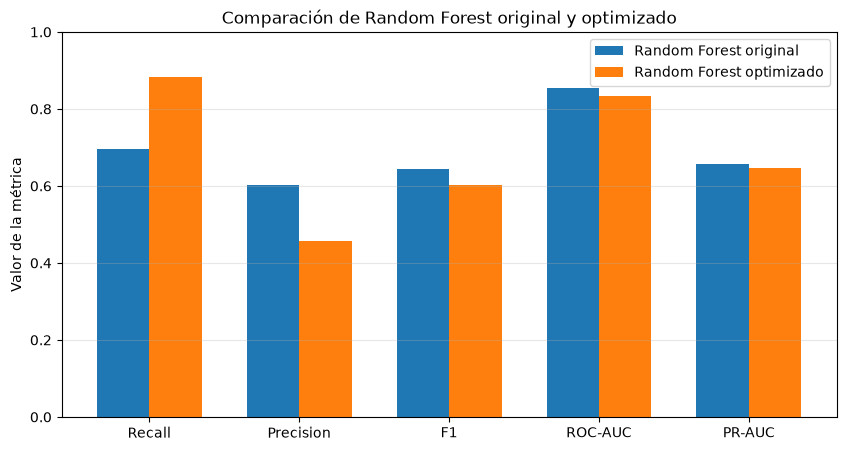

In [44]:
metricas = comparacion["Métrica"]
original = comparacion["Random Forest original"]
optimizado = comparacion["Random Forest optimizado"]

x = np.arange(len(metricas))
ancho = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - ancho / 2,
    original,
    ancho,
    label="Random Forest original"
)

plt.bar(
    x + ancho / 2,
    optimizado,
    ancho,
    label="Random Forest optimizado"
)

plt.xticks(x, metricas)
plt.ylim(0, 1)
plt.ylabel("Valor de la métrica")
plt.title("Comparación de Random Forest original y optimizado")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [19]:
modelo_rf_optimizado = busqueda_rf.best_estimator_

print("Modelo optimizado guardado correctamente.")

Modelo optimizado guardado correctamente.


In [20]:
from sklearn.model_selection import cross_val_predict

modelo_rf_optimizado = busqueda_rf.best_estimator_

# Probabilidades de validación cruzada
probabilidades_cv = cross_val_predict(
    modelo_rf_optimizado,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [ ]:
# Resumen estadístico de las probabilidades
print("Probabilidad mínima:", probabilidades_cv.min())
print("Probabilidad máxima:", probabilidades_cv.max())
print("Probabilidad promedio:", probabilidades_cv.mean())

print("\nDistribución de probabilidades:")
print(
    pd.Series(probabilidades_cv).describe(
        percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

Probabilidad mínima: 0.43681656752649334
Probabilidad máxima: 0.5287444867813552
Probabilidad promedio: 0.4952843432620099

Distribución de probabilidades:
count    5634.000000
mean        0.495284
std         0.020097
min         0.436817
5%          0.455680
10%         0.462350
25%         0.483862
50%         0.500601
75%         0.510906
90%         0.517326
95%         0.519873
max         0.528744
dtype: float64


In [23]:
print("Mejores hiperparámetros:")
for parametro, valor in busqueda_rf.best_params_.items():
    print(f"{parametro}: {valor}")

print("\nMejor Recall en validación:")
print(busqueda_rf.best_score_)

Mejores hiperparámetros:
modelo__class_weight: balanced
modelo__max_depth: 30
modelo__max_features: log2
modelo__min_samples_leaf: 10
modelo__min_samples_split: 5
modelo__n_estimators: 290

Mejor Recall en validación:
0.8822742474916389


In [ ]:
from sklearn.model_selection import cross_val_predict
import pandas as pd

# Probabilidades del Random Forest original
probabilidades_original = cross_val_predict(
    pipelines["Random Forest"],
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Comparación de distribuciones
comparacion_probabilidades = pd.DataFrame({
    "Random Forest original": pd.Series(probabilidades_original).describe(),
    "Random Forest optimizado": pd.Series(probabilidades_cv).describe()
})

display(comparacion_probabilidades.round(4))

,Random Forest original,Random Forest optimizado
count,5634.0000,5634.0000
mean,0.3478,0.4953
std,0.2794,0.0201
min,0.0000,0.4368
25%,0.0950,0.4839
50%,0.2800,0.5006
75%,0.5800,0.5109
max,0.9850,0.5287


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score)

def calcular_recall_at_20(y_real, probabilidades):
    y_real = np.asarray(y_real)

    cantidad = int(np.ceil(len(y_real) * 0.20))

    # Seleccionar el 20% con mayor riesgo
    indices = np.argsort(probabilidades)[::-1][:cantidad]

    abandonos_detectados = y_real[indices].sum()
    total_abandonos = y_real.sum()

    return abandonos_detectados / total_abandonos


comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Random Forest original",
        "Random Forest optimizado"
    ],
    "ROC-AUC": [
        roc_auc_score(y_train, probabilidades_original),
        roc_auc_score(y_train, probabilidades_cv)
    ],
    "PR-AUC": [
        average_precision_score(y_train, probabilidades_original),
        average_precision_score(y_train, probabilidades_cv)
    ],
    "Recall@20%": [
        calcular_recall_at_20(y_train, probabilidades_original),
        calcular_recall_at_20(y_train, probabilidades_cv)
    ]
})

display(comparacion_modelos.round(3))

,Modelo,ROC-AUC,PR-AUC,Recall@20%
0,Random Forest original,0.854,0.652,0.518
1,Random Forest optimizado,0.832,0.640,0.495


In [26]:
print("Mejores hiperparámetros encontrados:")

for parametro, valor in busqueda_rf.best_params_.items():
    print(f"{parametro}: {valor}")

Mejores hiperparámetros encontrados:
modelo__class_weight: balanced
modelo__max_depth: 30
modelo__max_features: log2
modelo__min_samples_leaf: 10
modelo__min_samples_split: 5
modelo__n_estimators: 290


### 9. RF optimizado por PR-AUC

In [27]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

parametros_rf_nuevo = {
    "modelo__n_estimators": randint(100, 401),
    "modelo__max_depth": [None, 10, 15, 20, 30],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 4, 6, 10],
    "modelo__max_features": ["sqrt", "log2"],
    "modelo__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}

busqueda_rf_nueva = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=parametros_rf_nuevo,
    n_iter=40,
    scoring={
        "recall": "recall",
        "precision": "precision",
        "f1": "f1",
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision"
    },
    refit="pr_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

busqueda_rf_nueva.fit(X_train, y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'modelo__class_weight': [None, 'balanced', ...], 'modelo__max_depth': [None, 10, ...], 'modelo__max_features': ['sqrt', 'log2'], 'modelo__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",40
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'f1': 'f1', 'pr_auc': 'average_precision', 'precision': 'precision', 'recall': 'recall', ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'pr_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold`

In [28]:
print("Mejores hiperparámetros:")
print(busqueda_rf_nueva.best_params_)

print("\nMejor PR-AUC promedio:")
print(round(busqueda_rf_nueva.best_score_, 4))

Mejores hiperparámetros:
{'modelo__class_weight': 'balanced_subsample', 'modelo__max_depth': 20, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 10, 'modelo__n_estimators': 228}

Mejor PR-AUC promedio:
0.6693


In [29]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score

modelo_rf_nuevo = busqueda_rf_nueva.best_estimator_

probabilidades_nuevo = cross_val_predict(
    modelo_rf_nuevo,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

comparacion_final_rf = pd.DataFrame({
    "Modelo": [
        "Random Forest original",
        "Random Forest optimizado por Recall",
        "Random Forest optimizado por PR-AUC"
    ],
    "ROC-AUC": [
        roc_auc_score(y_train, probabilidades_original),
        roc_auc_score(y_train, probabilidades_cv),
        roc_auc_score(y_train, probabilidades_nuevo)
    ],
    "PR-AUC": [
        average_precision_score(y_train, probabilidades_original),
        average_precision_score(y_train, probabilidades_cv),
        average_precision_score(y_train, probabilidades_nuevo)
    ],
    "Recall@20%": [
        calcular_recall_at_20(y_train, probabilidades_original),
        calcular_recall_at_20(y_train, probabilidades_cv),
        calcular_recall_at_20(y_train, probabilidades_nuevo)
    ]
})

display(comparacion_final_rf.round(3))

,Modelo,ROC-AUC,PR-AUC,Recall@20%
0,Random Forest original,0.854,0.652,0.518
1,Random Forest optimizado por Recall,0.832,0.640,0.495
2,Random Forest optimizado por PR-AUC,0.855,0.665,0.518


In [ ]:
from sklearn.model_selection import cross_val_predict

# Pipeline de Regresión Logística
modelo_logistico = pipelines["Regresión Logística"]

# Probabilidades mediante validación cruzada
probabilidades_logistica = cross_val_predict(
    modelo_logistico,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Probabilidades calculadas correctamente.")
print("Cantidad de predicciones:", len(probabilidades_logistica))

Probabilidades calculadas correctamente.
Cantidad de predicciones: 5634


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Modelos y probabilidades de validación
modelos_comparacion = {
    "Regresión Logística": probabilidades_logistica,
    "Random Forest original": probabilidades_original,
    "RF optimizado por Recall": probabilidades_cv,
    "RF optimizado por PR-AUC": probabilidades_nuevo
}

# Cálculo de métricas para todos los modelos
resultados = []

for nombre, probabilidades in modelos_comparacion.items():

    resultados.append({
        "Modelo": nombre,
        "ROC-AUC": roc_auc_score(
            y_train, probabilidades
        ),
        "PR-AUC": average_precision_score(
            y_train, probabilidades
        ),
        "Recall@20%": calcular_recall_at_20(
            y_train, probabilidades
        )
    })

# Tabla comparativa
tabla_comparacion = pd.DataFrame(resultados)

# Orden por Recall@20%
tabla_comparacion = tabla_comparacion.sort_values(
    by="Recall@20%",
    ascending=False
)

display(tabla_comparacion.round(3))

,Modelo,ROC-AUC,PR-AUC,Recall@20%
1,Random Forest original,0.854,0.652,0.518
3,RF optimizado por PR-AUC,0.855,0.665,0.518
0,Regresión Logística,0.851,0.658,0.516
2,RF optimizado por Recall,0.832,0.640,0.495


In [ ]:
from sklearn.model_selection import cross_val_predict

# Pipeline del Árbol de Decisión
modelo_arbol = pipelines["Árbol de Decisión"]

# Probabilidades mediante validación cruzada
probabilidades_arbol = cross_val_predict(
    modelo_arbol,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Probabilidades del Árbol de Decisión calculadas correctamente.")
print("Cantidad de predicciones:", len(probabilidades_arbol))

Probabilidades del Árbol de Decisión calculadas correctamente.
Cantidad de predicciones: 5634


### 10. Resultados de validación cruzada

In [33]:
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

resultados = []

for nombre, probabilidades in modelos_comparacion.items():

    # Clasificación con umbral 0.50
    predicciones = (probabilidades >= 0.50).astype(int)

    resultados.append({
        "Modelo": nombre,
        "Recall": recall_score(y_train, predicciones),
        "Precision": precision_score(
            y_train, predicciones, zero_division=0
        ),
        "F1": f1_score(y_train, predicciones),
        "ROC-AUC": roc_auc_score(y_train, probabilidades),
        "PR-AUC": average_precision_score(y_train, probabilidades),
        "Recall@20%": calcular_recall_at_20(
            y_train, probabilidades
        )
    })

tabla_final_modelos = pd.DataFrame(resultados)

tabla_final_modelos = tabla_final_modelos.sort_values(
    by=["Recall@20%", "PR-AUC"],
    ascending=False
).reset_index(drop=True)

display(tabla_final_modelos.round(3))

,Modelo,Recall,Precision,F1,ROC-AUC,PR-AUC,Recall@20%
0,RF optimizado por PR-AUC,0.757,0.565,0.647,0.855,0.665,0.518
1,Random Forest original,0.698,0.601,0.646,0.854,0.652,0.518
2,Regresión Logística,0.564,0.657,0.607,0.851,0.658,0.516
3,RF optimizado por Recall,0.882,0.456,0.601,0.832,0.640,0.495


In [34]:
# Modelos candidatos
modelos_finalistas = {
    "Random Forest optimizado por PR-AUC": busqueda_rf_nueva.best_estimator_,
    "Regresión Logística": pipelines["Regresión Logística"]
}

In [35]:
print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])

print("\nDistribución de abandono en entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribución de abandono en prueba:")
print(y_test.value_counts(normalize=True).round(3))

Registros de entrenamiento: 5634
Registros de prueba: 1409

Distribución de abandono en entrenamiento:
Churn Label
0    0.735
1    0.265
Name: proportion, dtype: float64

Distribución de abandono en prueba:
Churn Label
0    0.735
1    0.265
Name: proportion, dtype: float64


In [ ]:
from sklearn.base import clone

# Modelos finalistas
modelos_finalistas = {
    "Random Forest optimizado por PR-AUC": clone(
        busqueda_rf_nueva.best_estimator_
    ),
    "Regresión Logística": clone(
        pipelines["Regresión Logística"]
    )
}

# Entrenamiento de modelos con datos de training
for nombre, modelo in modelos_finalistas.items():
    modelo.fit(X_train, y_train)
    print(f"{nombre}: entrenamiento completado")

Random Forest optimizado por PR-AUC: entrenamiento completado
Regresión Logística: entrenamiento completado


In [ ]:
# Anulación de advertencia sobre categorías desconocidas que no afectan al análisis.
import warnings

warnings.filterwarnings(
    "ignore",
    message="Found unknown categories in columns.*during transform",
    category=UserWarning
)

### 11. Resultados de prueba

In [ ]:
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

resultados_test = []
predicciones_test = {}
probabilidades_test = {}

for nombre, modelo in modelos_finalistas.items():

    # Predicciones sobre el conjunto de prueba
    y_pred = modelo.predict(X_test)

    # Probabilidades estimadas de abandono
    y_prob = modelo.predict_proba(X_test)[:, 1]

    # Guardado de resultados 
    predicciones_test[nombre] = y_pred
    probabilidades_test[nombre] = y_prob

    # Cálculo de métricas
    resultados_test.append({
        "Modelo": nombre,
        "Recall": recall_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob),
        "Recall@20%": calcular_recall_at_20(
            y_test, y_prob
        )
    })

tabla_test = pd.DataFrame(resultados_test)

display(tabla_test.round(3))

,Modelo,Recall,Precision,F1,ROC-AUC,PR-AUC,Recall@20%
0,Random Forest optimizado por PR-AUC,0.746,0.549,0.633,0.846,0.647,0.505
1,Regresión Logística,0.553,0.618,0.584,0.841,0.636,0.492


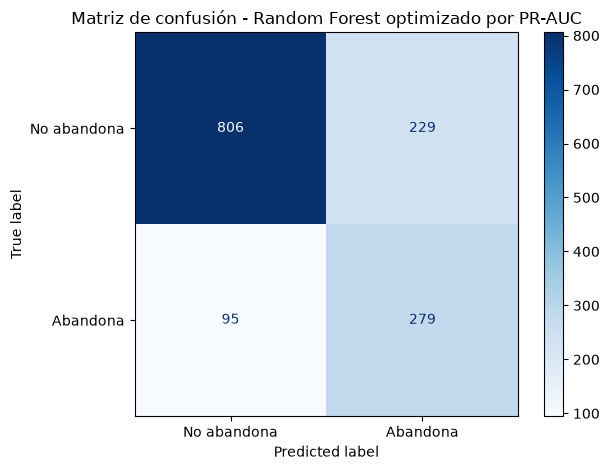

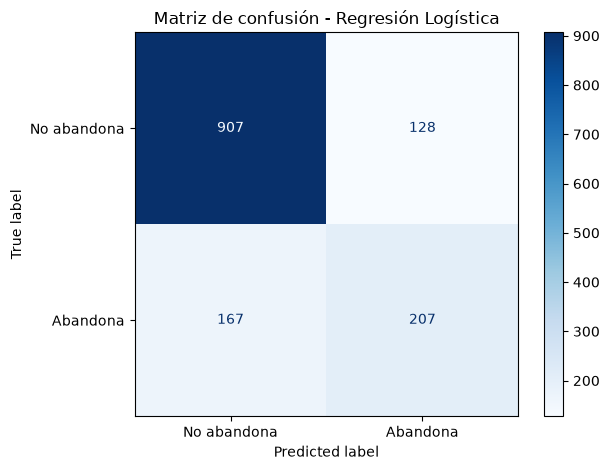

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

for nombre, y_pred in predicciones_test.items():

    matriz = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["No abandona", "Abandona"]
    )

    disp.plot(cmap="Blues", values_format="d")

    plt.title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.show()

In [40]:
resultados_comerciales = []

for nombre, probabilidades in probabilidades_test.items():

    cantidad_contactar = int(
        np.ceil(len(y_test) * 0.20)
    )

    indices_ordenados = np.argsort(
        probabilidades
    )[::-1]

    indices_seleccionados = indices_ordenados[
        :cantidad_contactar
    ]

    abandonos_detectados = y_test.iloc[
        indices_seleccionados
    ].sum()

    total_abandonos = y_test.sum()

    resultados_comerciales.append({
        "Modelo": nombre,
        "Clientes a contactar": cantidad_contactar,
        "Abandonos detectados": int(abandonos_detectados),
        "Total abandonos reales": int(total_abandonos),
        "Recall@20%": (
            abandonos_detectados / total_abandonos
        )
    })

tabla_comercial = pd.DataFrame(resultados_comerciales)

display(tabla_comercial.round(3))

,Modelo,Clientes a contactar,Abandonos detectados,Total abandonos reales,Recall@20%
0,Random Forest optimizado por PR-AUC,282,189,374,0.505
1,Regresión Logística,282,184,374,0.492


In [41]:
tabla_validacion = pd.DataFrame({
    "Modelo": [
        "Random Forest optimizado por PR-AUC",
        "Regresión Logística"
    ],
    "Recall_validacion": [0.757, 0.564],
    "Precision_validacion": [0.565, 0.658],
    "F1_validacion": [0.647, 0.607],
    "ROC-AUC_validacion": [0.855, 0.851],
    "PR-AUC_validacion": [0.665, 0.658],
    "Recall@20%_validacion": [0.518, 0.516]
})

# Unir con los resultados del test
comparacion_final = tabla_validacion.merge(
    tabla_test,
    on="Modelo"
)

display(comparacion_final.round(3))

,Modelo,Recall_validacion,Precision_validacion,F1_validacion,ROC-AUC_validacion,PR-AUC_validacion,Recall@20%_validacion,Recall,Precision,F1,ROC-AUC,PR-AUC,Recall@20%
0,Random Forest optimizado por PR-AUC,0.757,0.565,0.647,0.855,0.665,0.518,0.746,0.549,0.633,0.846,0.647,0.505
1,Regresión Logística,0.564,0.658,0.607,0.851,0.658,0.516,0.553,0.618,0.584,0.841,0.636,0.492


### 12. Comparación final

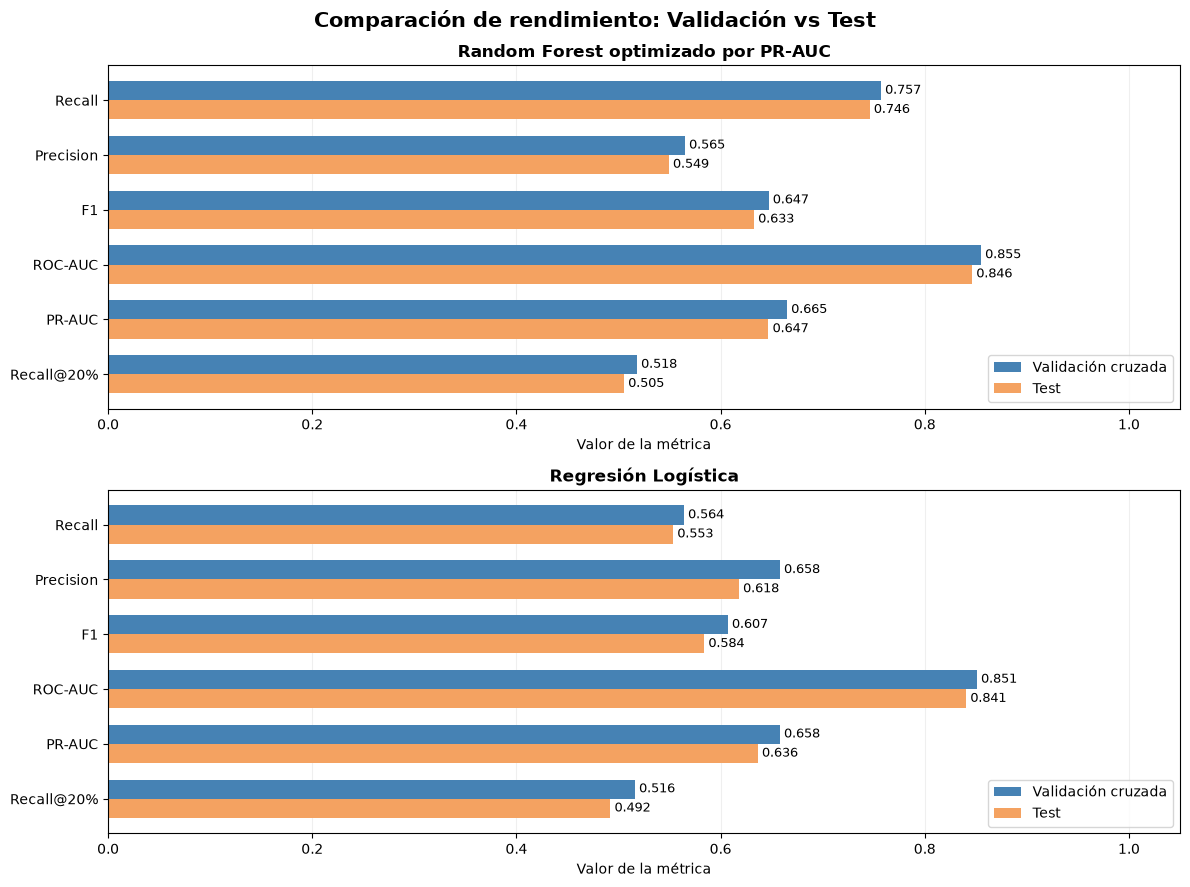

In [ ]:
# Resultados preliminares de validación cruzada
metricas = [
    "Recall", "Precision", "F1",
    "ROC-AUC", "PR-AUC", "Recall@20%"
]

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

for ax, (_, fila) in zip(axes, comparacion_final.iterrows()):

    valores_validacion = [
        fila[f"{metrica}_validacion"]
        for metrica in metricas
    ]

    valores_test = [
        fila[metrica]
        for metrica in metricas
    ]

    y = np.arange(len(metricas))
    ancho = 0.35

    barras_val = ax.barh(
        y - ancho/2,
        valores_validacion,
        ancho,
        label="Validación cruzada",
        color="#4682B4"
    )

    barras_test = ax.barh(
        y + ancho/2,
        valores_test,
        ancho,
        label="Test",
        color="#F4A261"
    )

    ax.set_yticks(y)
    ax.set_yticklabels(metricas)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.05)

    ax.set_title(fila["Modelo"], fontweight="bold")
    ax.set_xlabel("Valor de la métrica")

    ax.bar_label(barras_val, fmt="%.3f", padding=3, fontsize=9)
    ax.bar_label(barras_test, fmt="%.3f", padding=3, fontsize=9)

    ax.legend(loc="lower right")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

plt.suptitle(
    "Comparación de rendimiento: Validación vs Test",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()